# Regressão linear com validação: dá para melhorar escolhendo melhor?

## Por que este notebook existe

A LH Nautical só vai trocar a régua do notebook 04 (média da categoria na loja × sazonalidade × tendência) por um modelo se ele prever melhor a venda dos **próximos 3 meses** de cada produto em cada loja. No notebook 05, a regressão linear não conseguiu.

Antes de descartá-la falta uma pergunta justa: **uma regressão linear bem ajustada** (quais features usar, quantos meses de histórico no treino, quanta regularização) supera a régua? Para responder sem "colar no gabarito", os ajustes são escolhidos numa **validação** separada e o **teste é aberto uma única vez neste notebook**, no fim. Uma ressalva: esse período de teste já foi visto nos notebooks 04 e 05, e a ideia de testar janelas de treino mais curtas nasceu de olhar o teste no 05. A separação daqui vale para as escolhas feitas neste notebook, não para o teste como um todo.

## Resposta curta

**Não, e o teste mostrou que a escolha da validação enganava.**

- **Na validação**, o melhor entre 80 candidatos (Linear 4, treinado só nos últimos 12 cortes, Ridge com alpha = 10.000) parecia melhor que a régua: erro de 12,2% contra 13,2% por categoria no local, ganhando em 9 de 12 meses.
- **No teste**, foi o **pior modelo linear**: erro de 21,8% por categoria no local contra 11,9% da régua e 12,6% do modelo do notebook 05, com viés de −17,8% (o do notebook 05 era −7,7%).
- Isso é compatível com **sobreajuste à validação** (entre 80 candidatos, um sempre parece bom por sorte) ou com uma mudança de período; este experimento não separa as duas explicações.
- O modelo do notebook 05 (o Linear 4, o melhor dos quatro no teste daquele notebook) continua sendo o melhor modelo linear, e a régua continua sendo a nota a superar.

O ganho deste notebook é de método: agora sabemos disso **sem ter escolhido, neste notebook, nada olhando o teste** (com a ressalva acima).

## O que a validação decide

| Escolha | Opções |
|---|---|
| Conjunto de features | Os 4 do notebook 05 (Linear 1 a 4) |
| Janela de treino | Todos os cortes anteriores, ou só os últimos 24, 18 ou 12 (testa a hipótese do notebook 05 de que o crescimento mudou de regime) |
| Regularização | Regressão linear simples, ou **Ridge** com alpha crescente. O Ridge aplica uma "multa" a pesos grandes, para o modelo não depender de uma feature só |

Os termos técnicos (validação, sobreajuste, Ridge, erro ÷ régua) estão explicados no apêndice.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics_ai.demand_common import add_months, comparison_scorecard, cutoff_wape, scorecard_vs_ruler
from src.analytics_ai.demand_linear import (
    ESSENTIAL_FEATURES,
    GROUP_FEATURES,
    HISTORY_FEATURES,
    RULER_FEATURE,
    fit_linear,
    load_linear_panel,
    predict_nonnegative,
)
from src.analytics_ai.demand_plots import COLORS as CORES
from src.analytics_ai.demand_plots import comparison_chart
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100

config = MlFeatureConfig.from_environment_monthly()
TABELA_FEATURES = f"{config.catalog}.{config.schema}.ml_features_produto_loja_mes"

## 1. Dados

As mesmas features e o mesmo tratamento do notebook 05 (grupos e justificativa lá e em `docs/dicionario_features_ml_produto_loja_mes.md`). A diferença é que agora **a validação decide** quais grupos ficam.

In [2]:
ESSENCIAIS = ESSENTIAL_FEATURES
REGUA = RULER_FEATURE
HISTORICO = HISTORY_FEATURES
GRUPO_EXTRA = GROUP_FEATURES

# Uma única leitura do Databricks: só linhas com alvo conhecido e tendência pronta
# (os primeiros cortes não têm 24 meses de histórico).
dados, descartadas = load_linear_panel(spark, TABELA_FEATURES)

print(f"linhas lidas: {len(dados) + descartadas:,} | descartadas por valor ausente: {descartadas:,}")
print(f"cortes: {dados['cutoff'].min()} a {dados['cutoff'].max()} ({dados['cutoff'].nunique()} cortes)")

linhas lidas: 322,578 | descartadas por valor ausente: 1,658
cortes: 2021-12-01 a 2026-05-01 (54 cortes)


## 2. Dividir o tempo em treino, validação e teste

Pense num aluno: ele estuda com **exercícios de casa** (treino), faz um **simulado** para descobrir qual método de estudo funciona melhor (validação) e só então faz a **prova final** (teste). Se usasse a prova final para escolher o método, a nota dela não diria mais nada sobre problemas novos.

```
passado ────────────────────────────────────────────────────────────────────────► hoje
[ treino de seleção ]  (3m)  [ validação: 12 cortes ]  (3m)  [ teste: 12 cortes ]
 └────────────────── treino final = tudo até 3 meses antes do teste ─────────────┘
```

- **Teste:** os mesmos 12 cortes do notebook 04 e do 05, para comparar com a régua e com o modelo anterior de igual para igual.
- **Validação:** os 12 cortes anteriores ao teste. São 12 porque **12 meses cobrem um ciclo sazonal completo**, e a sazonalidade é a feature que mais pesa: uma validação curta premiaria modelos bons só numa estação.
- **Treino de seleção:** tudo até 3 meses antes da validação. Cada candidato aprende aqui, e a validação diz qual foi melhor.
- **Folga de 3 meses entre os blocos:** o alvo olha 3 meses à frente. Sem a folga, o alvo da última linha de um bloco cairia dentro do seguinte.
- **Treino final:** depois de escolher, o vencedor é treinado de novo com treino + validação (o mesmo treino do notebook 05).

In [3]:
cortes = sorted(dados["cutoff"].unique())
CORTES_TESTE = cortes[-12:]
ULTIMO_CORTE_FINAL = add_months(CORTES_TESTE[0], -3)  # fim do treino final (= notebook 05)
CORTES_VAL = [c for c in cortes if c <= ULTIMO_CORTE_FINAL][-12:]
ULTIMO_CORTE_SELECAO = add_months(CORTES_VAL[0], -3)  # fim do treino de seleção

treino_selecao = dados[dados["cutoff"] <= ULTIMO_CORTE_SELECAO].copy()
validacao = dados[dados["cutoff"].isin(CORTES_VAL)].copy()
treino_final = dados[dados["cutoff"] <= ULTIMO_CORTE_FINAL].copy()  # seleção + folga + validação
teste = dados[dados["cutoff"].isin(CORTES_TESTE)].copy()

# Guardas contra vazamento: o alvo de cada bloco termina antes do próximo começar.
assert len(CORTES_VAL) == 12 and len(CORTES_TESTE) == 12
assert add_months(treino_selecao["cutoff"].max(), 3) <= validacao["cutoff"].min()
assert add_months(validacao["cutoff"].max(), 3) <= teste["cutoff"].min()
assert add_months(treino_final["cutoff"].max(), 3) <= teste["cutoff"].min()

blocos = pd.DataFrame(
    {
        "bloco": ["treino de seleção", "validação", "treino final (seleção + validação)", "teste"],
        "linhas": [len(b) for b in (treino_selecao, validacao, treino_final, teste)],
        "cortes": [b["cutoff"].nunique() for b in (treino_selecao, validacao, treino_final, teste)],
        "primeiro corte": [str(b["cutoff"].min())[:7] for b in (treino_selecao, validacao, treino_final, teste)],
        "último corte": [str(b["cutoff"].max())[:7] for b in (treino_selecao, validacao, treino_final, teste)],
    }
).set_index("bloco")
display(blocos)
print(f"séries por corte no teste: {len(teste) / len(CORTES_TESTE):,.0f} (notebook 04: 6.054)")

# Referências do notebook 04, recalculadas a partir das colunas da tabela de features.
for base in (validacao, teste):
    base["pred_mm3"] = base["sum_3m"]
    base["pred_mm12"] = base["sum_12m"] / 12 * 3
    base["pred_mm12_idx"] = base["sum_12m"] / 12 * base["season_sum_next_3m"]

,linhas,cortes,primeiro corte,último corte
bloco,,,,
treino de seleção,151426,26,2021-12,2024-01
validação,72637,12,2024-04,2025-03
treino final (seleção + validação),236164,40,2021-12,2025-03
teste,72648,12,2025-06,2026-05


séries por corte no teste: 6,054 (notebook 04: 6.054)


**O que o resultado mostra:** o teste é idêntico ao do notebook 04 e do 05 (12 cortes, 6.054 séries por corte), e o treino final (dez/21 a mar/25) é o mesmo do notebook 05. O custo da divisão é que o treino de seleção fica com 26 cortes, contra os 40 do notebook 05. As conferências (`assert`) passaram: em nenhum bloco o alvo invade o bloco seguinte.

## 3. Como medimos

As mesmas medidas do notebook 05 (erro por produto × loja, por categoria no local e por local; viés; MAE; RMSE) e a mesma regra: um método só é "melhor" se ganhar da régua **na maioria dos 12 meses**. Para **escolher** na validação usamos o **erro por categoria no local**, que é o que separa os métodos (o erro por produto é dominado pelo acaso).

## 4. Testar 80 candidatos na validação

Cada candidato é uma combinação de features (4), janela de treino (4) e modelo (5: linear simples e Ridge com alpha = 1, 100, 10.000 e 1.000.000). Todos aprendem no treino de seleção e são medidos na validação.

Sobre o Ridge: as features têm escalas muito diferentes, então são padronizadas antes; sem isso, a "multa" cairia só sobre as de escala menor. Os alphas são grandes de propósito, porque com dezenas de milhares de linhas um alpha pequeno não muda nada.

In [4]:
FEATURES = {
    "Linear 1: essenciais": ESSENCIAIS,
    "Linear 2: + régua pronta": [*ESSENCIAIS, REGUA],
    "Linear 3: + histórico da série": [*ESSENCIAIS, REGUA, *HISTORICO],
    "Linear 4: + produto nos outros locais": [*ESSENCIAIS, REGUA, *HISTORICO, *GRUPO_EXTRA],
}
JANELAS = {"todos os cortes": None, "últimos 24": 24, "últimos 18": 18, "últimos 12": 12}
ALPHAS = [None, 1, 100, 10_000, 1_000_000]  # None = regressão linear simples, sem regularização
LINEAR_4 = FEATURES["Linear 4: + produto nos outros locais"]
COL = "erro por categoria no local (%)"


def nome_modelo(alpha):
    return "Linear simples" if alpha is None else f"Ridge (alpha={alpha:,})".replace(",", ".")


regua_val_por_corte = cutoff_wape(validacao, REGUA)

linhas, especs = [], []
for (nome_feat, colunas), (nome_jan, n_jan), alpha in itertools.product(FEATURES.items(), JANELAS.items(), ALPHAS):
    validacao["_pred"] = predict_nonnegative(fit_linear(treino_selecao, colunas, n_jan, alpha), validacao, colunas)
    nota = comparison_scorecard(validacao, {"x": "_pred"}).iloc[0]
    linhas.append(
        {
            "features": nome_feat,
            "janela de treino": nome_jan,
            "modelo": nome_modelo(alpha),
            COL: nota["wape_categoria_local"] * 100,
            "erro por local (%)": nota["wape_local"] * 100,
            "viés (%)": nota["vies"] * 100,
            "cortes ganhos da régua (de 12)": int((cutoff_wape(validacao, "_pred") < regua_val_por_corte).sum()),
        }
    )
    especs.append((nome_feat, nome_jan, alpha))
grade = pd.DataFrame(linhas)
validacao = validacao.drop(columns="_pred")

regua_val = comparison_scorecard(validacao, {"Régua final": REGUA}).loc["Régua final", "wape_categoria_local"] * 100
print(f"{len(grade)} candidatos avaliados na validação | régua na validação: {regua_val:.1f}% por categoria no local")
display(grade.sort_values(COL).head(5).round(2).reset_index(drop=True))

80 candidatos avaliados na validação | régua na validação: 13.2% por categoria no local


,features,janela de treino,modelo,erro por categoria no local (%),erro por local (%),viés (%),cortes ganhos da régua (de 12)
0,Linear 4: + produto nos outros locais,últimos 12,Ridge (alpha=10.000),12.20,7.98,-5.85,9
1,Linear 3: + histórico da série,últimos 12,Ridge (alpha=10.000),12.23,8.03,-5.90,9
2,Linear 2: + régua pronta,últimos 12,Ridge (alpha=10.000),12.38,8.27,-5.88,9
3,Linear 1: essenciais,últimos 12,Ridge (alpha=100),12.65,8.76,-6.92,7
4,Linear 1: essenciais,últimos 12,Ridge (alpha=1),12.66,8.77,-6.95,7


**O que a tabela mostra** (os 5 melhores dos 80): o **vencedor** é Linear 4 + últimos 12 cortes + Ridge (alpha = 10.000), com 12,2% por categoria no local, 8,0% por local e viés de −5,9%, ganhando da régua (13,2%) em 9 de 12 meses da validação. Os três primeiros diferem só nas features, por décimos de ponto: não dá para dizer que um conjunto é melhor que outro.

O gráfico mostra, para cada valor de cada escolha, o **melhor** resultado que ele alcançou (a linha tracejada é a régua; a pontilhada, o modelo do notebook 05).

Ridge (alpha=1.000.000): erro de 32.1% (não aparece no gráfico)


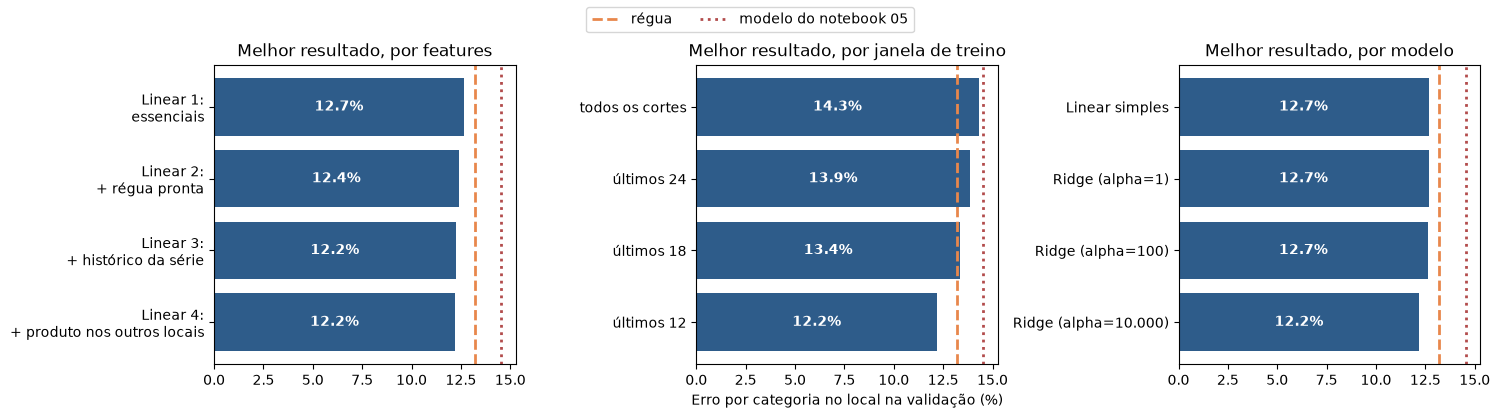

,melhor erro na validação (%)
features,
Linear 1: essenciais,12.65
Linear 2: + régua pronta,12.38
Linear 3: + histórico da série,12.23
Linear 4: + produto nos outros locais,12.20


,melhor erro na validação (%)
janela de treino,
todos os cortes,14.30
últimos 24,13.86
últimos 18,13.36
últimos 12,12.20


,melhor erro na validação (%)
modelo,
Linear simples,12.66
Ridge (alpha=1),12.66
Ridge (alpha=100),12.65
Ridge (alpha=10.000),12.20


In [5]:
idx_receita_04 = especs.index(("Linear 4: + produto nos outros locais", "todos os cortes", None))
receita_val = grade.loc[idx_receita_04, COL]

# Ridge com alpha = 1.000.000 zera os pesos e estoura a escala: fica fora do gráfico.
ALPHA_COLAPSADO = nome_modelo(1_000_000)
print(f"{ALPHA_COLAPSADO}: erro de {grade.loc[grade['modelo'] == ALPHA_COLAPSADO, COL].min():.1f}% (não aparece no gráfico)")
grade_grafico = grade[grade["modelo"] != ALPHA_COLAPSADO]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for ax, eixo in zip(axes, ["features", "janela de treino", "modelo"]):
    melhor = grade_grafico.groupby(eixo, sort=False)[COL].min()
    barras = ax.barh([str(v).replace(": ", ":\n") for v in melhor.index], melhor.values, color=CORES[0])
    ax.bar_label(barras, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
    ax.axvline(regua_val, color=CORES[1], linestyle="--", linewidth=2, label="régua")
    ax.axvline(receita_val, color=CORES[3], linestyle=":", linewidth=2, label="modelo do notebook 05")
    ax.set_title(f"Melhor resultado, por {eixo}")
    ax.invert_yaxis()
axes[1].set_xlabel("Erro por categoria no local na validação (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()
# Mesmos valores do gráfico, em tabela.
for eixo in ["features", "janela de treino", "modelo"]:
    display(grade_grafico.groupby(eixo, sort=False)[COL].min().round(2).to_frame("melhor erro na validação (%)"))


**O que o gráfico mostra:**

- **A janela de treino é a escolha que mais mexe na nota:** 14,3% com todos os cortes, 13,9% com 24, 13,4% com 18 e 12,2% com 12. Quanto mais curta, melhor na validação.
- **O conjunto de features quase não importa:** de 12,7% (Linear 1) a 12,2% (Linear 4). O histórico da série e as features de grupo seguem sem trazer quase nada.
- **Ridge com alpha de 1 a 100 dá o mesmo que a regressão simples.** Só alpha = 10.000 ajuda um pouco (12,2% contra 12,7%). Com alpha = 1.000.000 os pesos quase zeram e o erro sobe para 32,1%.
- **A régua na validação (13,2%) é mais fraca que no teste (11,9%):** a validação é um período mais difícil. Por isso, adiante, comparamos "erro ÷ régua" no mesmo período.

**Sinal de alerta:** o ganho vem quase todo de **uma** escolha (a janela curta), e 12 cortes contêm cada mês do ano **uma única vez**. O modelo aprende um ano só, incluindo o crescimento daquele ano.

## 5. O vencedor da validação

Duas checagens da regra do notebook 04: o vencedor precisa **ganhar da régua na maioria dos 12 meses** e **reduzir o viés** do modelo do notebook 05. Ainda não olhamos o teste.

In [6]:
idx_venc = grade[COL].idxmin()
venc_feat, venc_jan, venc_alpha = especs[idx_venc]
colunas_venc = FEATURES[venc_feat]
print(f"vencedor da validação: {venc_feat} | janela: {venc_jan} | modelo: {nome_modelo(venc_alpha)}")

comparativo_val = grade.loc[[idx_receita_04, idx_venc], [COL, "erro por local (%)", "viés (%)", "cortes ganhos da régua (de 12)"]]
comparativo_val.index = ["Modelo do notebook 05 (Linear 4)", "Vencedor da validação"]
nota_regua_val = comparison_scorecard(validacao, {"Régua final": REGUA}).iloc[0]
comparativo_val.loc["Régua final"] = [
    nota_regua_val["wape_categoria_local"] * 100,
    nota_regua_val["wape_local"] * 100,
    nota_regua_val["vies"] * 100,
    np.nan,
]
display(comparativo_val.round(2))

vencedor da validação: Linear 4: + produto nos outros locais | janela: últimos 12 | modelo: Ridge (alpha=10.000)


,erro por categoria no local (%),erro por local (%),viés (%),cortes ganhos da régua (de 12)
Modelo do notebook 05 (Linear 4),14.54,11.46,-10.58,5.0
Vencedor da validação,12.20,7.98,-5.85,9.0
Régua final,13.21,8.77,-3.47,NaN


**O que a tabela mostra:** o vencedor passa nas duas checagens: ganha da régua em **9 de 12 meses** (o modelo do notebook 05 ganhava em 5) e reduz o viés de −10,6% para −5,9%. O viés ainda é pior que o da régua (−3,5%). Pela regra da validação, é o modelo a levar para o teste; falta saber se a vantagem **se repete em dados que ninguém usou para escolher**.

## 6. Abrir o teste, uma única vez

O vencedor é **treinado de novo com treino + validação** (mais dados, incluindo o período mais recente) e medido no teste. Também recalculamos o modelo do notebook 05 no mesmo treino final: ele deve reproduzir os números de lá (12,6% por categoria no local, 8,5% por local, viés de −7,7%), o que confirma que a divisão não mudou.

**Daqui em diante nenhuma escolha é refeita.**

In [7]:
# O vencedor é treinado de novo com treino + validação e medido no teste, uma única vez.
modelo_venc = fit_linear(treino_final, colunas_venc, JANELAS[venc_jan], venc_alpha)
teste["pred_venc"] = predict_nonnegative(modelo_venc, teste, colunas_venc)

# Modelo do notebook 05, no mesmo treino final (deve reproduzir os números de lá).
teste["pred_nb05"] = predict_nonnegative(fit_linear(treino_final, LINEAR_4), teste, LINEAR_4)

### A validação prometeu o que o teste entregou?

Se o vencedor parece ótimo na validação e cai no teste, a escolha foi **sobreajuste à validação**. Como os dois períodos têm dificuldades diferentes, o erro bruto engana; a coluna **erro ÷ régua** mede o modelo em relação à régua **no mesmo período**. Abaixo de 1, o modelo ganha da régua.

In [8]:
# Na validação, os dois modelos são treinados só no treino de seleção (como na escolha).
validacao["pred_venc"] = predict_nonnegative(fit_linear(treino_selecao, colunas_venc, JANELAS[venc_jan], venc_alpha), validacao, colunas_venc)
validacao["pred_nb05"] = predict_nonnegative(fit_linear(treino_selecao, LINEAR_4), validacao, LINEAR_4)

linhas = []
for periodo, base in (("validação", validacao), ("teste", teste)):
    nota_regua = comparison_scorecard(base, {"x": REGUA}).iloc[0]
    for rotulo, coluna in (("Linear 4 (notebook 05)", "pred_nb05"), ("Vencedor da validação", "pred_venc")):
        nota = comparison_scorecard(base, {"x": coluna}).iloc[0]
        linhas.append(
            {
                "modelo": rotulo,
                "período": periodo,
                COL: nota["wape_categoria_local"] * 100,
                "erro ÷ régua (categoria no local)": nota["wape_categoria_local"] / nota_regua["wape_categoria_local"],
                "erro ÷ régua (local)": nota["wape_local"] / nota_regua["wape_local"],
                "viés (%)": nota["vies"] * 100,
            }
        )
display(pd.DataFrame(linhas).set_index(["modelo", "período"]).round(2))

,,erro por categoria no local (%),erro ÷ régua (categoria no local),erro ÷ régua (local),viés (%)
modelo,período,,,,
Linear 4 (notebook 05),validação,14.54,1.10,1.31,-10.58
Vencedor da validação,validação,12.20,0.92,0.91,-5.85
Linear 4 (notebook 05),teste,12.63,1.06,1.39,-7.70
Vencedor da validação,teste,21.75,1.83,3.39,-17.76


**O que a tabela mostra:**

- **O vencedor prometeu ganhar da régua e não ganhou.** Na validação, o erro dele por categoria no local era **0,92 da régua** (8% melhor); no teste virou **1,83** (83% pior). Por local, foi de 0,91 para 3,39.
- **O modelo do notebook 05 é estável:** 1,10 na validação e 1,06 no teste. Pior que a régua nos dois períodos, mas não muda de comportamento.
- **É compatível com sobreajuste à validação:** entre 80 candidatos, o que parece melhor tem boas chances de estar lá por sorte do período, e a escolha se apoiou numa única validação e numa janela de treino de só 12 cortes. Também pode ter havido mudança de período entre a validação e o teste; este experimento não separa as duas explicações.

**A causa exata não foi investigada.** Hipóteses: (1) um treino de 12 cortes contém cada mês uma vez só, então o modelo não separa sazonalidade do crescimento daquele ano; (2) o fim do treino (abr/24 a mar/25) pode ter crescimento diferente do de jun/25 em diante, e o viés de −17,8% aponta nessa direção.

## 7. Mês a mês no teste

Como nos notebooks 04 e 05, um método só é "melhor" se ganhar **na maioria dos 12 meses**.

Linear 4 (notebook 05) ganha da régua em 4 de 12 cortes: ['2025-09', '2025-10', '2025-11', '2026-03']
Vencedor da validação ganha da régua em 2 de 12 cortes: ['2025-07', '2025-08']


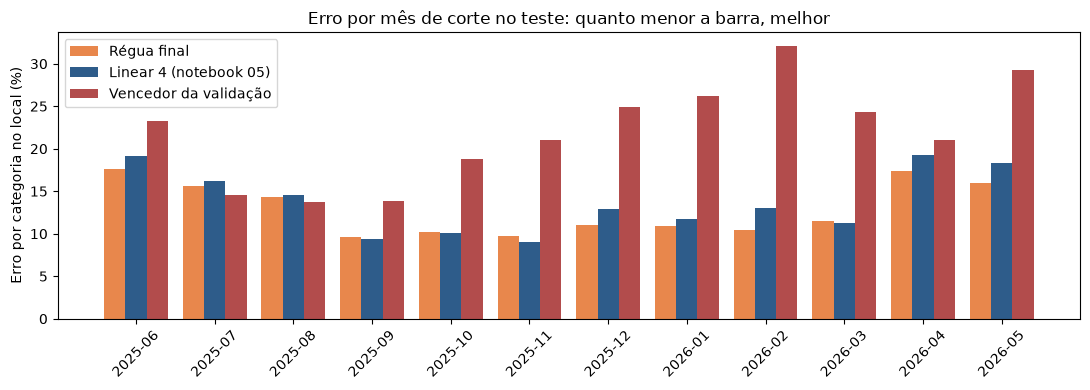

,Régua final,Linear 4 (notebook 05),Vencedor da validação
cutoff,,,
2025-06-01,17.6,19.1,23.3
2025-07-01,15.7,16.2,14.6
2025-08-01,14.3,14.6,13.7
2025-09-01,9.6,9.4,13.8
2025-10-01,10.2,10.0,18.8
2025-11-01,9.8,9.0,21.1
2025-12-01,11.0,12.9,24.9
2026-01-01,10.9,11.7,26.3
2026-02-01,10.5,13.1,32.1


In [9]:
por_corte = pd.DataFrame(
    {
        "Régua final": cutoff_wape(teste, REGUA),
        "Linear 4 (notebook 05)": cutoff_wape(teste, "pred_nb05"),
        "Vencedor da validação": cutoff_wape(teste, "pred_venc"),
    }
)
for modelo in ("Linear 4 (notebook 05)", "Vencedor da validação"):
    ganha = por_corte[modelo] < por_corte["Régua final"]
    print(f"{modelo} ganha da régua em {int(ganha.sum())} de {len(por_corte)} cortes: {[str(c)[:7] for c in ganha[ganha].index]}")

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(por_corte))
for k, (nome, cor) in enumerate(zip(por_corte.columns, [CORES[1], CORES[0], CORES[3]])):
    ax.bar(x + (k - 1) * 0.27, por_corte[nome] * 100, 0.27, color=cor, label=nome)
ax.set_xticks(x)
ax.set_xticklabels([str(c)[:7] for c in por_corte.index], rotation=45)
ax.set_ylabel("Erro por categoria no local (%)")
ax.set_title("Erro por mês de corte no teste: quanto menor a barra, melhor")
ax.legend()
plt.tight_layout()
plt.show()
# Mesmos valores do gráfico, em tabela (erro por categoria no local, %).
display((por_corte * 100).round(1))


**O que o resultado mostra:** o vencedor da validação ganha da régua em apenas **2 de 12 meses** (jul e ago/25). O modelo do notebook 05 ganhava em 4 (set, out e nov/25 e mar/26). Nos meses do meio do teste (set/25 a mar/26) o vencedor erra de 13,8% a 32,1% por categoria no local, contra 9,6% a 11,5% da régua; o pior mês é fev/26 (32,1% contra 10,5%). Pela regra do notebook 04, o vencedor não passa: o que foi bem na validação não se sustentou.

## 8. Comparação final com a régua e as médias móveis

O quadro segue o formato da seção 14 do notebook 04 (a "nota a superar") e acrescenta o modelo do notebook 05 e o vencedor da validação.

,Erro por produto × loja (%),Erro por categoria no local (%),Erro por local (%),Viés (%),MAE (unidades),RMSE (unidades),Cortes ganhos da régua (de 12)
previsao,,,,,,,
MM3,120.47,49.58,48.72,-1.93,6.93,9.46,0
MM12,99.23,36.35,35.50,-8.08,5.71,7.40,0
MM12 × índice,93.10,15.07,12.03,-11.68,5.36,7.13,0
Régua final,86.57,11.91,6.09,-2.75,4.98,6.38,–
Linear 4 (notebook 05),85.79,12.63,8.46,-7.70,4.94,6.39,4
Vencedor da validação,85.99,21.75,20.64,-17.76,4.95,6.50,2


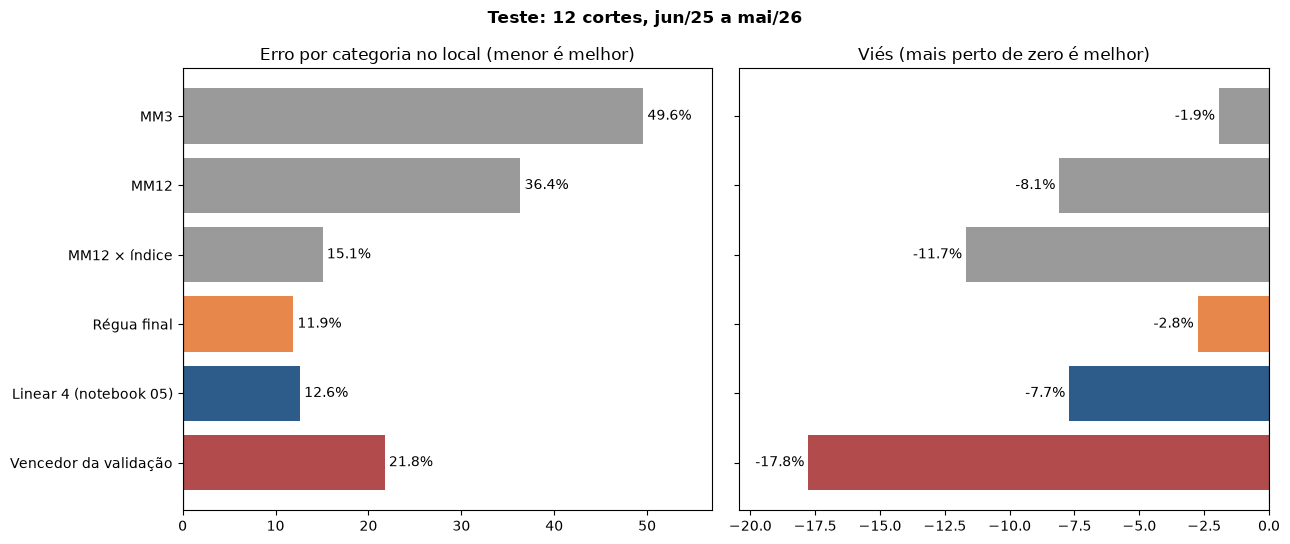

In [10]:
METODOS = {
    "MM3": "pred_mm3",
    "MM12": "pred_mm12",
    "MM12 × índice": "pred_mm12_idx",
    "Régua final": REGUA,
    "Linear 4 (notebook 05)": "pred_nb05",
    "Vencedor da validação": "pred_venc",
}
quadro = scorecard_vs_ruler(teste, METODOS, ruler_col=REGUA)
display(quadro)
comparison_chart(quadro, "Teste: 12 cortes, jun/25 a mai/26")
plt.show()

**O que o quadro mostra:**

- **A régua segue vencendo** nas medidas que importam para a decisão: 11,9% por categoria no local, 6,1% por local e viés de −2,8%.
- **O modelo do notebook 05** fica perto por categoria no local (12,6%), mas perde por local (8,5%) e no viés (−7,7%). Ganha da régua em 4 de 12 meses.
- **O vencedor da validação** erra 21,8% por categoria no local e 20,6% por local, com viés de −17,8%: pior até que a MM12 × índice (15,1% e 12,0%) e só melhor que a MM12 e a MM3.
- **Por produto × loja, os modelos empatam com a régua** (86,0% contra 86,6%), mas o RMSE do vencedor é pior (6,50 contra 6,38). O erro por produto é dominado pelo acaso e **não enxerga o problema**; quem enxerga é o erro somado e o viés.

## Conclusão

**Veredito: a validação não trouxe melhora. O melhor modelo linear continua sendo o do notebook 05, e a régua do notebook 04 continua sendo a nota a superar.**

- **Escolher no teste escondia um problema.** No notebook 05 o teste era juiz e nota final. Com uma validação separada, o modelo que "ganhou" a escolha perdeu no teste. Sem essa separação, um resultado assim poderia ter sido reportado como melhora.
- **O teste não é virgem.** Os notebooks 04 e 05 já o usaram, e a ideia de janelas curtas veio de olhar o teste no 05. Se algum modelo tivesse vencido, o resultado precisaria de um teste novo (por exemplo, os meses que ainda vão acontecer) antes de valer como prova. Como nenhum venceu, o veredito não depende disso.
- **Uma única validação de 12 cortes é frágil para escolher entre 80 candidatos.** Ela premiou a janela de treino curta, e o modelo treinado assim não se sustentou nos 12 meses seguintes.
- **Features e Ridge quase não mexem na nota:** a diferença entre os conjuntos de features é de décimos de ponto.
- **A régua pronta como feature e a sazonalidade** seguem sendo o que importa, como no notebook 05.

**Para a LH Nautical:** seguir usando a régua para planejar compra e estoque.

**Próximos passos:**

1. **Validação em várias dobras** (a cada dobra a validação anda 3 ou 6 meses e o treino cresce), escolhendo o candidato pela **média das dobras** e exigindo janelas de treino de pelo menos 24 cortes. É a forma de saber se algum ajuste linear realmente ganha, e não só parece ganhar.
2. **Modelos que aprendem interações** (árvores e *gradient boosting*) e a **regressão de Poisson**, com este mesmo desenho (treino, validação e teste com folga de 3 meses) e as mesmas medidas.
3. **Guardar o modelo escolhido** e gerar a previsão dos cortes recentes (`is_target_complete = false`) só quando algum modelo superar a régua no teste.

---

## Apêndice

### Glossário

| Termo | O que quer dizer, em palavras simples |
|---|---|
| Treino | Os dados com que o modelo aprende os pesos |
| **Validação** | Dados que o modelo não viu no treino, usados para **comparar candidatos e escolher**. É o "simulado" |
| **Teste** | Dados que ninguém usou para decidir nada, abertos **uma vez só** para a nota final. É a "prova" |
| Hiperparâmetro | Uma escolha que **não é aprendida** pelo modelo e que nós fazemos: quais features, qual janela de treino, quanta regularização |
| Ridge | Regressão linear com uma "multa" sobre pesos grandes. Quanto maior o alpha, maior a multa |
| Sobreajuste (*overfitting*) | Escolher tanto em cima dos mesmos dados que a nota parece boa ali e não se repete em dados novos |
| Erro ÷ régua | Erro do modelo dividido pelo erro da régua no mesmo período. Abaixo de 1, o modelo ganha |
| Folga de 3 meses | Espaço entre blocos para o alvo (3 meses à frente) de um bloco não invadir o seguinte |

### Limitações deste experimento

- **Uma única validação de 12 cortes.** A escolha pode ter sido decidida pela sorte de um período. Não sabemos quanto do problema é isso e quanto é a janela curta.
- **O vencedor combina janela curta e Ridge com alpha alto**, e não isolamos qual dos dois causou a queda no teste. Isolar exige avaliar cada um separadamente no teste, o que só é válido em um novo desenho de validação.
- **A causa do viés de −17,8% não foi investigada.**
- **O treino de seleção é 14 cortes menor que o do notebook 05** (26 contra 40), o que também pode ter favorecido janelas curtas.